# 📈 Linear Regression from Scratch (for Beginners)

In this notebook we build a **machine learning model from scratch** using only NumPy.
No scikit-learn, no magic: just the maths you learned, turned into code.

**The problem:** can we predict a student's **exam score** from the **hours they studied**?

**What we will do, step by step**

1. Create and look at the data
2. Define the model (a straight line)
3. Measure how wrong the model is (the cost function)
4. Improve the model automatically (gradient descent)
5. Check that our result is correct
6. Experiment with the learning rate
7. Make predictions

## Step 0: Import the tools

- **NumPy** does fast maths on lists of numbers (arrays).
- **Matplotlib** draws charts.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Step 1: The data

Real projects start with real data. To keep things simple we will **generate** our own data
so that we *know* the true answer and can check whether our model finds it.

We pretend that the real rule of the world is:

$$\text{score} = 35 + 5 \times \text{hours studied} + \text{some random noise}$$

(So a student who studies 0 hours gets about 35, and every extra hour adds about 5 marks.)
The random noise is there because real life is never perfectly neat.

Some vocabulary you will see everywhere in ML:

| Symbol | Meaning | In our problem |
|---|---|---|
| `x` | the **input** (feature) | hours studied |
| `y` | the **output** (target / label) | exam score |
| `m` | number of training examples | 100 students |

In [2]:
rng = np.random.default_rng(42)        # fixed seed -> same "random" numbers every run
m = 100                                # number of students

x = rng.uniform(0, 10, m)              # hours studied: random numbers between 0 and 10
y = 35 + 5 * x + rng.normal(0, 4, m)   # exam score = 35 + 5*hours + noise

print("First 5 students:")
for i in range(5):
    print(f"  studied {x[i]:.1f} hours  ->  scored {y[i]:.1f}")

First 5 students:
  studied 7.7 hours  ->  scored 75.3
  studied 4.4 hours  ->  scored 53.3
  studied 8.6 hours  ->  scored 76.4
  studied 7.0 hours  ->  scored 75.1
  studied 0.9 hours  ->  scored 38.3


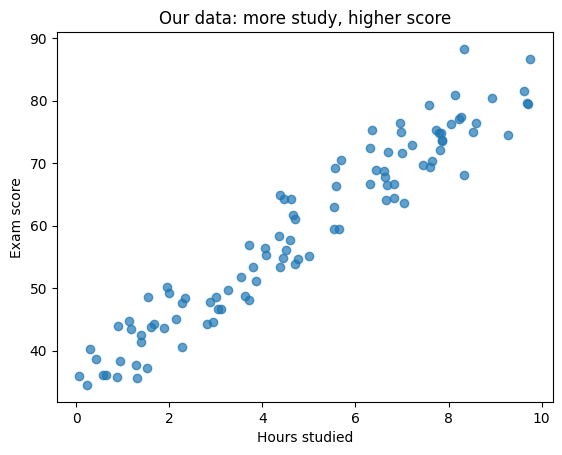

In [3]:
plt.scatter(x, y, alpha=0.7)
plt.xlabel("Hours studied")
plt.ylabel("Exam score")
plt.title("Our data: more study, higher score")
plt.show()

Each dot is one student. You can *see* the pattern: the dots go up and to the right.
Our job is to find the **best straight line** through these dots.

## Step 2: The model (a straight line)

You know the equation of a line from school: $y = mx + c$.
In machine learning we write it as:

$$\hat{y} = w \cdot x + b$$

- $\hat{y}$ ("y-hat") is the model's **prediction**.
- $w$ is the **weight** (slope): how many marks each extra hour adds.
- $b$ is the **bias** (intercept): the score at 0 hours.

**Training a model means finding the best values of $w$ and $b$.**

Let's write this as a function and try a bad guess first: $w = 2,\ b = 20$.

In [4]:
def predict(x, w, b):
    # The model: a straight line
    return w * x + b

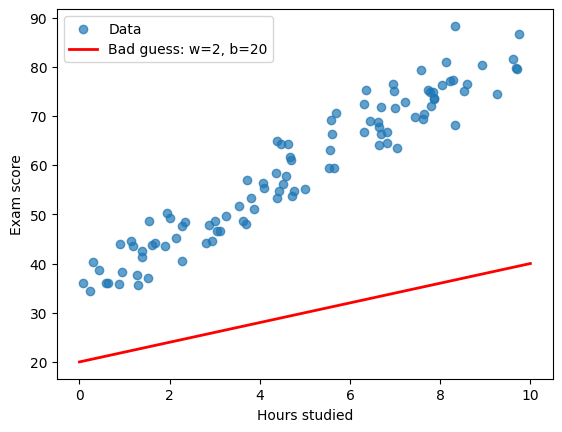

In [5]:
w_guess, b_guess = 2, 20

plt.scatter(x, y, alpha=0.7, label="Data")
xs = np.linspace(0, 10, 100)
plt.plot(xs, predict(xs, w_guess, b_guess), color="red", linewidth=2,
         label=f"Bad guess: w={w_guess}, b={b_guess}")
plt.xlabel("Hours studied")
plt.ylabel("Exam score")
plt.legend()
plt.show()

The red line is clearly too low and too flat. We need a way to **measure how bad** it is.
That is what the cost function does.

## Step 3: The cost function (how wrong are we?)

For one student, the **error** is the gap between the prediction and the truth:

$$\text{error} = \hat{y} - y$$

To get one number for *all* students we:

1. **Square** each error (so negatives don't cancel positives, and big mistakes are punished more)
2. **Add them up** and **average** them

This is the **Mean Squared Error** cost function:

$$J(w, b) = \frac{1}{2m} \sum_{i=1}^{m} \left( \hat{y}_i - y_i \right)^2$$

(The extra $\tfrac{1}{2}$ is just a convenience: it cancels a "2" when we take the derivative later.)

**Big cost = bad line. Small cost = good line.** Training means *making the cost as small as possible*.

In [6]:
def compute_cost(x, y, w, b):
    m = len(x)
    errors = predict(x, w, b) - y          # prediction minus truth, for every student
    return np.sum(errors ** 2) / (2 * m)   # square, add up, divide by 2m

In [7]:
print("Cost of our bad guess  (w=2, b=20): ", round(compute_cost(x, y, 2, 20), 2))
print("Cost of a better guess (w=5, b=35): ", round(compute_cost(x, y, 5, 35), 2))

Cost of our bad guess  (w=2, b=20):  478.18
Cost of a better guess (w=5, b=35):  7.68


The better line has a **much lower cost**. 

But we can't guess forever. We need the computer to find the best $w$ and $b$ by itself.

## Step 4: Gradient descent (how the model learns)

**Analogy:** imagine you're standing on a foggy hill and want to reach the bottom.
You can't see far, but you can feel which direction slopes downward under your feet.
So you take a small step downhill, feel the slope again, step again, and repeat until the ground is flat.

- The **hill** is the cost function $J(w, b)$.
- Your **position** is the current $(w, b)$.
- The **slope under your feet** is the **gradient** (the derivatives).
- The **step size** is the **learning rate** $\alpha$.

### The gradients

Using calculus on our cost function, the slopes are:

$$\frac{\partial J}{\partial w} = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}_i - y_i)\, x_i
\qquad\qquad
\frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}_i - y_i)$$

### The update rule

$$w := w - \alpha \frac{\partial J}{\partial w}
\qquad\qquad
b := b - \alpha \frac{\partial J}{\partial b}$$

The minus sign means "go **opposite** to the slope", i.e. downhill.

In [8]:
def compute_gradients(x, y, w, b):
    m = len(x)
    errors = predict(x, w, b) - y
    dw = np.sum(errors * x) / m     # slope of the cost with respect to w
    db = np.sum(errors) / m         # slope of the cost with respect to b
    return dw, db

### One single step, by hand

Before running the full loop, let's watch **one** step so nothing feels like magic.

In [9]:
w, b = 0.0, 0.0          # start knowing nothing
alpha = 0.02             # learning rate

print(f"Before step: w={w:.3f}, b={b:.3f}, cost={compute_cost(x, y, w, b):.2f}")

dw, db = compute_gradients(x, y, w, b)
print(f"Gradients  : dw={dw:.3f}, db={db:.3f}  (negative = increasing w and b will lower the cost)")

w = w - alpha * dw
b = b - alpha * db
print(f"After step : w={w:.3f}, b={b:.3f}, cost={compute_cost(x, y, w, b):.2f}")

Before step: w=0.000, b=0.000, cost=1858.51
Gradients  : dw=-325.813, db=-59.280  (negative = increasing w and b will lower the cost)
After step : w=6.516, b=1.186, cost=363.76


The cost dropped after just one step. Now we simply **repeat this thousands of times**.

## Step 5: The full training loop

We wrap the steps in a loop. Each pass through the loop is called an **iteration** (or epoch, when all data is used once).
We also save the cost at every iteration so we can plot the learning curve afterwards.

In [10]:
def gradient_descent(x, y, alpha=0.02, n_iters=5000):
    w, b = 0.0, 0.0                      # 1. start from zero
    cost_history = []

    for i in range(n_iters):
        dw, db = compute_gradients(x, y, w, b)   # 2. which way is downhill?
        w = w - alpha * dw                       # 3. take a step
        b = b - alpha * db
        cost_history.append(compute_cost(x, y, w, b))   # 4. record progress

        if i % 1000 == 0:
            print(f"Iteration {i:5d} | cost = {cost_history[-1]:8.3f} | w = {w:.3f} | b = {b:.3f}")

    return w, b, cost_history

w, b, cost_history = gradient_descent(x, y)
print(f"\nFinal model: score = {w:.2f} * hours + {b:.2f}")

Iteration     0 | cost =  363.762 | w = 6.516 | b = 1.186
Iteration  1000 | cost =    7.683 | w = 5.080 | b = 34.483
Iteration  2000 | cost =    7.671 | w = 5.031 | b = 34.792
Iteration  3000 | cost =    7.671 | w = 5.031 | b = 34.795
Iteration  4000 | cost =    7.671 | w = 5.031 | b = 34.795

Final model: score = 5.03 * hours + 34.79


Look at the numbers: $w$ and $b$ started at 0 and moved towards roughly 5 and 35, the true values we used to create the data. 
**The model discovered the rule by itself.**

## Step 6: See the result

Two pictures tell the whole story:

- **Left:** the line the model learned, fitting the data.
- **Right:** the cost falling as training progresses (the "learning curve").

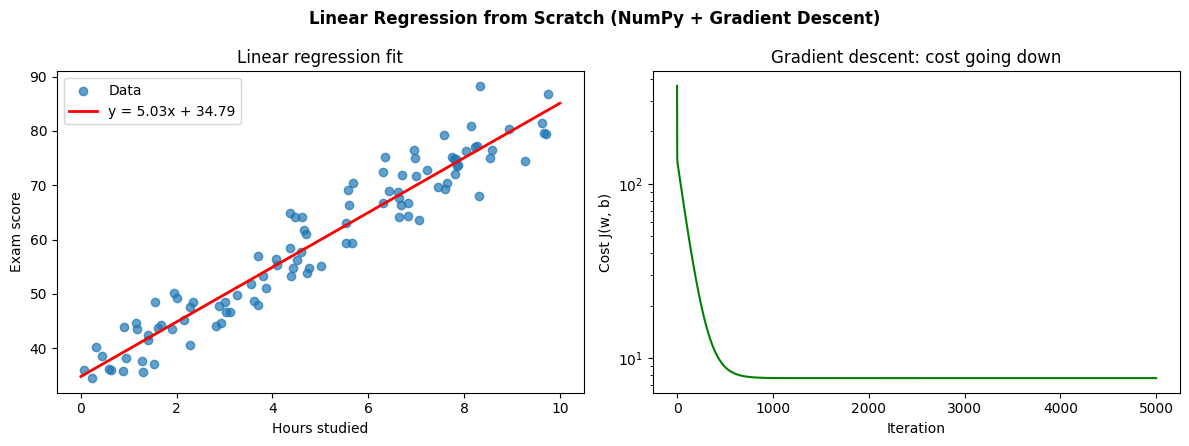

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: data and fitted line
axes[0].scatter(x, y, alpha=0.7, label="Data")
axes[0].plot(xs, predict(xs, w, b), color="red", linewidth=2, label=f"y = {w:.2f}x + {b:.2f}")
axes[0].set_xlabel("Hours studied")
axes[0].set_ylabel("Exam score")
axes[0].set_title("Linear regression fit")
axes[0].legend()

# Right: cost over time
axes[1].plot(cost_history, color="green")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Cost J(w, b)")
axes[1].set_title("Gradient descent: cost going down")
axes[1].set_yscale("log")   # log scale so the early big drop and later small changes are both visible

plt.suptitle("Linear Regression from Scratch (NumPy + Gradient Descent)", fontweight="bold")
plt.tight_layout()
plt.savefig("linear_regression_result.png", dpi=150)
plt.show()

The cost drops very fast at the start (big slope = big steps) and then flattens out
(the ground becomes flat near the bottom). **Flat curve = the model has converged.**

## Step 7: Is our answer actually correct?

NumPy can solve linear regression directly with a formula (no loop). If our gradient descent is right,
we should get the **same** answer.

We also compute **R²**, a score for "how much of the variation in exam scores does our model explain?"
(1.0 = perfect, 0 = no better than just guessing the average).

In [12]:
w_ref, b_ref = np.polyfit(x, y, 1)       # direct formula solution
print(f"Our gradient descent : w = {w:.3f}, b = {b:.3f}")
print(f"np.polyfit (check)   : w = {w_ref:.3f}, b = {b_ref:.3f}")

y_pred = predict(x, w, b)
ss_res = np.sum((y - y_pred) ** 2)       # error left over after using the model
ss_tot = np.sum((y - y.mean()) ** 2)     # error if we only guessed the average
r2 = 1 - ss_res / ss_tot
print(f"\nR² score = {r2:.3f}")

Our gradient descent : w = 5.031, b = 34.795
np.polyfit (check)   : w = 5.031, b = 34.795

R² score = 0.924


The numbers match, so our from-scratch implementation is correct ✅

## Step 8: Experiment with the learning rate

The learning rate $\alpha$ is the size of each step downhill. Choosing it matters a lot:

- **Too small** → tiny steps, learning takes forever.
- **Just right** → smooth, fast convergence.
- **Too large** → you overshoot the bottom and the cost **explodes**.

Let's try all three. (We use fewer iterations just to see the behaviour.)

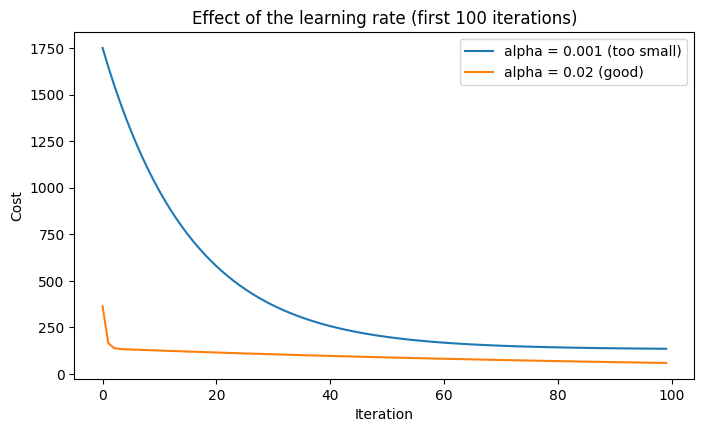

In [13]:
def run(alpha, n_iters=100):
    w, b, history = 0.0, 0.0, []
    for _ in range(n_iters):
        dw, db = compute_gradients(x, y, w, b)
        w -= alpha * dw
        b -= alpha * db
        history.append(compute_cost(x, y, w, b))
    return history

plt.figure(figsize=(8, 4.5))
plt.plot(run(0.001), label="alpha = 0.001 (too small)")
plt.plot(run(0.02),  label="alpha = 0.02 (good)")
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Effect of the learning rate (first 100 iterations)")
plt.legend()
plt.show()

Now the dangerous one. With $\alpha = 0.1$ each step is so big that we jump from one side of the valley to the other,
landing higher each time.

In [14]:
bad = run(0.1, n_iters=10)
print("Cost with alpha = 0.1 over the first 10 iterations:")
for i, c in enumerate(bad, start=1):
    print(f"  iteration {i:2d}: cost = {float(c):,.0f}")

Cost with alpha = 0.1 over the first 10 iterations:
  iteration  1: cost = 8,357
  iteration  2: cost = 39,459
  iteration  3: cost = 188,224
  iteration  4: cost = 899,707
  iteration  5: cost = 4,302,358
  iteration  6: cost = 20,575,384
  iteration  7: cost = 98,400,337
  iteration  8: cost = 470,594,294
  iteration  9: cost = 2,250,593,272
  iteration 10: cost = 10,763,349,279


The cost **grows** instead of shrinking. If you ever see this in your own projects, the fix is almost always: **lower the learning rate**.

## Step 9: Use the model to predict

Now that the model is trained, we can ask it about students it has never seen.

In [15]:
for hours in [2, 5, 8]:
    print(f"A student who studies {hours} hours is predicted to score {predict(hours, w, b):.1f}")

A student who studies 2 hours is predicted to score 44.9
A student who studies 5 hours is predicted to score 59.9
A student who studies 8 hours is predicted to score 75.0


## 🎉 Summary

| Concept | One-line meaning |
|---|---|
| **Model** | $\hat{y} = wx + b$, a line whose shape is set by $w$ and $b$ |
| **Cost function** | One number measuring how wrong the model is (lower = better) |
| **Gradient** | The slope of the cost: tells us which way is downhill |
| **Learning rate** | How big each downhill step is |
| **Gradient descent** | Repeat: compute gradient → take a step → until the cost stops falling |

## What to learn next

1. **Multiple linear regression**: more than one input (e.g. hours studied *and* hours slept)
2. **Feature scaling**: makes gradient descent faster when inputs have very different ranges
3. **Train/test split**: evaluate the model on data it has not seen
4. **Logistic regression**: the same ideas, but for yes/no predictions